# Data exploration

A closer look at every file in `data/` before building the layer. One section per source:

1. FHFA county HPI (both releases)
2. FHFA ZIP5 HPI (both releases)
3. Census county boundaries (2024, 1:500k)
4. Census ZCTA → county relationship file (2020)
5. ACS B25001 housing units (2020–2024 5-year)
6. Connecticut county → planning region crosswalk
7. Summary of findings

In [1]:
import io
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import openpyxl
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
FHFA_OLD = DATA / "fhfa"
FHFA_NEW = DATA / "fhfa" / "next_release"
CENSUS = DATA / "census"
TERRITORIES = {"60", "66", "69", "72", "78"}

## 1. FHFA county HPI

The sheet opens with a title, a blank row, a notes paragraph, the release date ("Last updated: ...") and "Not Seasonally Adjusted", and only then the header. We need the release date for `hpi_as_of(d)`.

In [2]:
def sheet_preamble(path, n=6):
    ws = openpyxl.load_workbook(path, read_only=True).worksheets[0]
    return [row[0] for row in ws.iter_rows(max_row=n, values_only=True)]

for p in (FHFA_OLD / "hpi_at_county.xlsx", FHFA_NEW / "hpi_at_county.xlsx"):
    print(p.relative_to(ROOT))
    for line in sheet_preamble(p):
        s = str(line)
        print("   ", s[:160] + "..." if len(s) > 160 else s)

data\fhfa\hpi_at_county.xlsx
    HPI for Counties (All-Transactions Index)
Experimental Indexes Showing Cumulative (Nominal) Annual Appreciation
    None
    * These annual county indexes should be considered developmental. As with the standard FHFA HPIs, revisions to these indexes may reflect the impact of new data ...
    Last updated: March 25, 2025.
    Not Seasonally Adjusted (NSA) 
    State
data\fhfa\next_release\hpi_at_county.xlsx
    HPI for Counties (All-Transactions Index)
Experimental Indexes Showing Cumulative (Nominal) Annual Appreciation
    None
    * These annual county indexes should be considered developmental. As with the standard FHFA HPIs, revisions to these indexes may reflect the impact of new data ...
    Last updated: March 31, 2026.
    Not Seasonally Adjusted (NSA) 
    State


In [3]:
def read_county(path):
    # pandas skips the blank 2nd row, so the header row is reached with skiprows=5
    df = pd.read_excel(path, skiprows=5, dtype={"FIPS code": str})
    return df.rename(columns={"State": "state", "County": "county", "FIPS code": "fips", "Year": "year",
                              "Annual Change (%)": "annual_change", "HPI": "hpi",
                              "HPI with 1990 base": "hpi_1990", "HPI with 2000 base": "hpi_2000"})

cty_old = read_county(FHFA_OLD / "hpi_at_county.xlsx")
cty_new = read_county(FHFA_NEW / "hpi_at_county.xlsx")
print(cty_old.dtypes)
cty_old.head()

state                str
county               str
fips                 str
year               int64
annual_change    float64
hpi              float64
hpi_1990         float64
hpi_2000         float64
dtype: object


,state,county,fips,year,annual_change,hpi,hpi_1990,hpi_2000
0,AL,Autauga,01001,1986,NaN,100.00,95.54,70.81
1,AL,Autauga,01001,1987,-1.86,98.14,93.76,69.49
2,AL,Autauga,01001,1988,2.60,100.68,96.19,71.29
3,AL,Autauga,01001,1989,4.30,105.02,100.33,74.36
4,AL,Autauga,01001,1990,-0.33,104.67,100.00,74.11


In [4]:
def profile(df, key):
    L = df["year"].max()
    has = lambda y: df.loc[(df.year == y) & df.hpi.notna(), key].nunique()
    return pd.Series({
        "rows": len(df),
        "units": df[key].nunique(),
        "years": f"{df['year'].min()}-{L}",
        "duplicate unit-years": df.duplicated([key, "year"]).sum(),
        "missing hpi": df["hpi"].isna().sum(),
        "units with hpi in latest year": has(L),
        "units with hpi in latest-1": has(L - 1),
        "units with hpi in latest-5": has(L - 5),
    })

pd.DataFrame({"old release": profile(cty_old, "fips"), "next release": profile(cty_new, "fips")})

,old release,next release
rows,103294,106252
units,2787,2795
years,1975-2024,1975-2025
duplicate unit-years,0,0
missing hpi,1015,1057
units with hpi in latest year,2633,2677
units with hpi in latest-1,2621,2666
units with hpi in latest-5,2766,2791


### Coverage over time

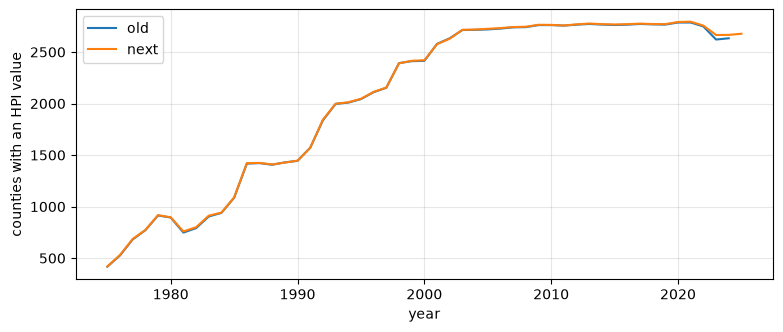

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for name, df in [("old", cty_old), ("next", cty_new)]:
    df[df.hpi.notna()].groupby("year")["fips"].nunique().plot(ax=ax, label=name)
ax.set_ylabel("counties with an HPI value"); ax.legend(); ax.grid(alpha=.3)

### Gaps inside series

A county can have a value, then missing years, then values again. The latest-year YoY and the 5-year CAGR must use exactly years L, L-1 and L-5, never "the last available value".

In [6]:
def gaps(df):
    g = df[df.hpi.notna()].groupby("fips")["year"].agg(["min", "max", "count"])
    g["span"] = g["max"] - g["min"] + 1
    return g[g["span"] != g["count"]]

gap_old = gaps(cty_old)
print(len(gap_old), "county series with internal gaps (old release)")
example = gap_old.index[0]
cty_old.loc[cty_old.fips == example, ["fips", "county", "year", "hpi", "annual_change"]].tail(15)

406

 county series with internal gaps (old release)


,fips,county,year,hpi,annual_change
577,01037,Coosa,2016,100.00,NaN
578,01037,Coosa,2017,106.69,6.69
579,01037,Coosa,2018,113.48,6.37
580,01037,Coosa,2019,123.56,8.88
581,01037,Coosa,2020,131.84,6.70
582,01037,Coosa,2021,141.91,7.64
583,01037,Coosa,2022,156.52,10.30
584,01037,Coosa,2023,NaN,NaN
585,01037,Coosa,2024,151.94,NaN


In [7]:
# Counties whose own last value comes before the release's latest year
for name, df in [("old", cty_old), ("next", cty_new)]:
    last = df[df.hpi.notna()].groupby("fips")["year"].max()
    print(name, "- last observed year per county:", last.value_counts().sort_index(ascending=False).head(6).to_dict())

old - last observed year per county: {2024: 2633, 2023: 68, 2022: 63, 2021: 22, 2020: 1}
next - last observed year per county: {2025: 2677, 2024: 54, 2023: 23, 2022: 22, 2021: 18, 2020: 1}


### Do `annual_change` and the HPI ratio agree?

If they do, we can compute YoY from `hpi` directly and use `annual_change` only as a check.

In [8]:
d = cty_new.sort_values(["fips", "year"]).copy()
d["prev"] = d.groupby("fips")["hpi"].shift()
d["prev_year"] = d.groupby("fips")["year"].shift()
d["calc"] = (d.hpi / d.prev - 1) * 100
both = d[d.annual_change.notna() & d.calc.notna() & (d.year - d.prev_year == 1)]
print("max |annual_change - computed|:", round((both.annual_change - both.calc).abs().max(), 3))
print("annual_change present where previous year missing:", (d.annual_change.notna() & d.prev.isna()).sum())

max |annual_change - computed|: 0.017
annual_change present where previous year missing: 0


### Distribution of the two layer metrics (latest year, published counties only)

,count,mean,std,min,25%,50%,75%,max
hpi_yoy_pct,2612.0,4.056279,5.655889,-23.967161,1.392899,3.816787,6.192766,53.039277
hpi_cagr_5y_pct,2674.0,8.782834,2.047247,0.586093,7.586920,8.894288,10.103453,18.901077


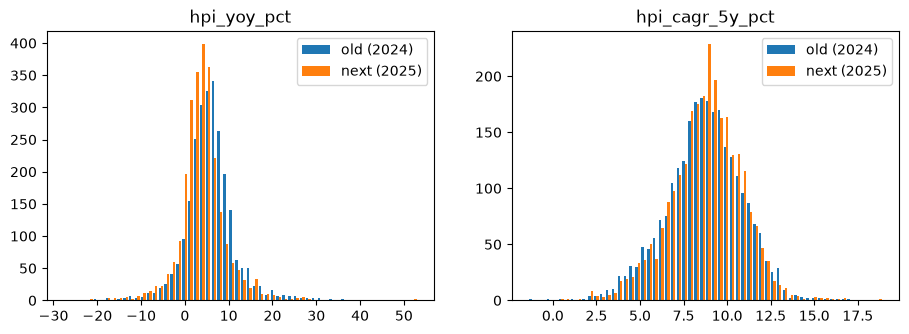

In [9]:
def metrics(df):
    L = df["year"].max()
    w = df.pivot(index="fips", columns="year", values="hpi")
    out = pd.DataFrame(index=w.index)
    out["hpi_yoy_pct"] = (w[L] / w[L - 1] - 1) * 100
    out["hpi_cagr_5y_pct"] = ((w[L] / w[L - 5]) ** (1 / 5) - 1) * 100
    return out

m_old, m_new = metrics(cty_old), metrics(cty_new)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col in zip(axes, m_old.columns):
    ax.hist([m_old[col].dropna(), m_new[col].dropna()], bins=60, label=["old (2024)", "next (2025)"])
    ax.set_title(col); ax.legend()
m_new.describe().T

In [10]:
# Extremes: worth sanity-checking before the Part 4 ranking
names = cty_new.drop_duplicates("fips").set_index("fips")[["state", "county"]]
m_new.join(names).dropna().sort_values("hpi_yoy_pct").iloc[[0, 1, 2, -3, -2, -1]]

,hpi_yoy_pct,hpi_cagr_5y_pct,state,county
fips,,,,
28101,-23.967161,3.085192,MS,Newton
54043,-21.468104,0.718495,WV,Lincoln
19151,-21.008317,7.394760,IA,Pocahontas
01037,50.517766,11.756641,AL,Coosa
38009,52.049375,11.257308,ND,Bottineau
29081,53.039277,18.901077,MO,Harrison


### Revisions between releases

FHFA re-estimates the whole history in each release, so old values change too.

In [11]:
rev = cty_old.merge(cty_new, on=["fips", "year"], suffixes=("_old", "_new"))
rev["diff"] = rev.hpi_new - rev.hpi_old
print("fips-years in both:", len(rev))
print("changed (|diff| > 0.005):", (rev["diff"].abs() > 0.005).sum())
print("became missing:", (rev.hpi_old.notna() & rev.hpi_new.isna()).sum(),
      "| became available:", (rev.hpi_old.isna() & rev.hpi_new.notna()).sum())
rev["diff"].describe()

fips-years in both: 102710
changed (|diff| > 0.005): 98672
became missing: 18 | became available: 99


count    101692.000000
mean          0.472902
std           9.648100
min        -259.160000
25%          -0.760000
50%           0.080000
75%           1.120000
max         455.160000
Name: diff, dtype: float64

In [12]:
print("FIPS only in old release: ", sorted(set(cty_old.fips) - set(cty_new.fips)))
print("FIPS only in next release:", sorted(set(cty_new.fips) - set(cty_old.fips)))

FIPS only in old release:  ['09001', '09003', '09005', '09007', '09009', '09011', '09013', '09015', '29181', '48069']


FIPS only in next release: ['02063', '02195', '09110', '09120', '09130', '09140', '09150', '09160', '09170', '09180', '09190', '13173', '20073', '20205', '21135', '48317', '48333', '48421']


## 2. FHFA ZIP5 HPI

Same layout, keyed by five-digit ZIP. This is the candidate source for filling blank counties in Part 2. The sheet has trailing empty columns, so only the first six are read.

In [13]:
def read_zip(path):
    df = pd.read_excel(path, skiprows=5, usecols=range(6), dtype={"Five-Digit ZIP Code": str})
    return df.rename(columns={"Five-Digit ZIP Code": "zip", "Year": "year", "Annual Change (%)": "annual_change",
                              "HPI": "hpi", "HPI with 1990 base": "hpi_1990", "HPI with 2000 base": "hpi_2000"})

zip_old = read_zip(FHFA_OLD / "hpi_at_zip5.xlsx")
zip_new = read_zip(FHFA_NEW / "hpi_at_zip5.xlsx")
pd.DataFrame({"old release": profile(zip_old, "zip"), "next release": profile(zip_new, "zip")})

,old release,next release
rows,668175,689533
units,18956,19024
years,1975-2024,1975-2025
duplicate unit-years,0,0
missing hpi,16775,19368
units with hpi in latest year,15315,15772
units with hpi in latest-1,14950,15627
units with hpi in latest-5,18242,18885


In [14]:
print("ZIP code lengths:", zip_new.zip.str.len().value_counts().to_dict())
print("ZIPs with a leading zero:", zip_new.zip.str.startswith("0").sum())
zip_new.head()

ZIP code lengths: {5: 689533}
ZIPs with a leading zero: 68225


,zip,year,annual_change,hpi,hpi_1990,hpi_2000
0,01001,1984,NaN,100.00,52.30,51.39
1,01001,1985,15.82,115.82,60.57,59.52
2,01001,1986,16.18,134.56,70.37,69.15
3,01001,1987,21.68,163.72,85.63,84.14
4,01001,1988,17.00,191.56,100.18,98.44


## 3. Census county boundaries (2024, 1:500k)

These supply the layer's geometry plus `geoid`, `name` (NAMELSAD, with suffix) and `state` (STUSPS).

In [15]:
BOUNDARIES = CENSUS / "cb_2024_us_county_500k.zip"
print(zipfile.ZipFile(BOUNDARIES).namelist())
counties_all = gpd.read_file(BOUNDARIES)
print("CRS:", counties_all.crs)
counties = counties_all[~counties_all.STATEFP.isin(TERRITORIES)].copy()
print("all features:", len(counties_all), "| 50 states + DC:", len(counties), "| states:", counties.STUSPS.nunique())
counties.drop(columns="geometry").head()

['cb_2024_us_county_500k.shp.ea.iso.xml', 'cb_2024_us_county_500k.shp.iso.xml', 'cb_2024_us_county_500k.shp', 'cb_2024_us_county_500k.shx', 'cb_2024_us_county_500k.dbf', 'cb_2024_us_county_500k.prj', 'cb_2024_us_county_500k.cpg']


CRS: EPSG:4269
all features: 3235 | 50 states + DC: 3144 | states: 51


,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER
0,01,069,00161560,0500000US01069,01069,Houston,Houston County,AL,Alabama,06,1501742250,4795418
1,01,023,00161537,0500000US01023,01023,Choctaw,Choctaw County,AL,Alabama,06,2365900084,19114321
2,01,113,00161583,0500000US01113,01113,Russell,Russell County,AL,Alabama,06,1660653961,15562947
3,10,005,00217269,0500000US10005,10005,Sussex,Sussex County,DE,Delaware,06,2424590442,674129051
4,01,071,00161561,0500000US01071,01071,Jackson,Jackson County,AL,Alabama,06,2792044612,126334711


In [16]:
print("unique GEOID:", counties.GEOID.is_unique)
print("invalid geometries:", (~counties.is_valid).sum())
print("geometry types:", counties.geom_type.value_counts().to_dict())
print("total vertices:", counties.geometry.count_coordinates().sum())

unique GEOID: True


invalid geometries: 0
geometry types: {'Polygon': 2966, 'MultiPolygon': 178}
total vertices: 1013880


In [17]:
# Features that cross the antimeridian (Aleutians); this matters for RFC 7946 GeoJSON
b = counties.bounds
counties.loc[(b.maxx - b.minx) > 180, ["GEOID", "NAMELSAD", "STUSPS"]].join(b)

,GEOID,NAMELSAD,STUSPS,minx,miny,maxx,maxy
2387,02016,Aleutians West Census Area,AK,-179.146711,51.215567,179.77847,57.249626


In [18]:
# How big would a naive, unsimplified GeoJSON be?
buf = io.BytesIO()
counties.to_crs(4326).to_file(buf, driver="GeoJSON")
print(f"naive GeoJSON size: {buf.getbuffer().nbytes / 1e6:.1f} MB (limit 8 MB)")

naive GeoJSON size: 29.4 MB (limit 8 MB)


### FHFA coverage against the boundary file

In [19]:
B = set(counties.GEOID)
for name, df in [("old", cty_old), ("next", cty_new)]:
    L = df.year.max()
    have_latest = set(df.loc[(df.year == L) & df.hpi.notna(), "fips"])
    print(f"{name}: FHFA FIPS not in boundaries: {sorted(set(df.fips) - B)}")
    print(f"{name}: boundary counties with an HPI for {L}: {len(B & have_latest)} / {len(B)}")

old: FHFA FIPS not in boundaries: ['09001', '09003', '09005', '09007', '09009', '09011', '09013', '09015']
old: boundary counties with an HPI for 2024: 2625 / 3144
next: FHFA FIPS not in boundaries: []
next: boundary counties with an HPI for 2025: 2677 / 3144


Text(0.5, 1.0, 'Next release: county has an FHFA HPI for 2025')

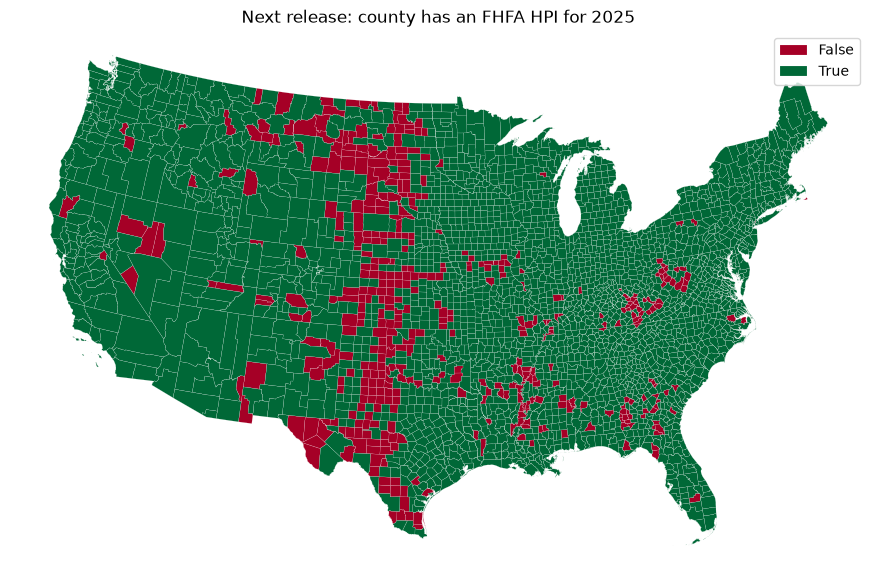

In [20]:
L = cty_new.year.max()
latest = cty_new.loc[cty_new.year == L].set_index("fips")["hpi"]
cov = counties.set_index("GEOID")
cov["has_hpi"] = cov.index.map(latest).notna()
lower48 = cov[~cov.STUSPS.isin(["AK", "HI"])]
ax = lower48.to_crs(5070).plot(column="has_hpi", categorical=True, legend=True, figsize=(12, 7),
                              cmap="RdYlGn", linewidth=0.1, edgecolor="white")
ax.set_axis_off(); ax.set_title(f"Next release: county has an FHFA HPI for {L}")

In [21]:
(cov.groupby("STUSPS")["has_hpi"].agg(total="size", with_hpi="sum")
    .assign(missing=lambda t: t.total - t.with_hpi)
    .sort_values("missing", ascending=False).head(15))

,total,with_hpi,missing
STUSPS,,,
TX,254,176,78
KS,105,64,41
NE,93,62,31
ND,53,23,30
SD,66,37,29
GA,159,131,28
OK,77,55,22
KY,120,98,22
AK,30,8,22


## 4. ZCTA → county relationship file (2020)

Pipe-delimited, with one row per ZCTA × county intersection and the land and water area of each part. Rows with an empty ZCTA are county areas that no ZCTA covers.

In [22]:
rel = pd.read_csv(CENSUS / "tab20_zcta520_county20_natl.txt", sep="|", dtype=str, encoding="utf-8-sig")
for c in ["AREALAND_PART", "AREAWATER_PART", "AREALAND_ZCTA5_20", "AREALAND_COUNTY_20"]:
    rel[c] = pd.to_numeric(rel[c])
print(rel.shape)
rel.head()

(47863, 18)


,OID_ZCTA5_20,GEOID_ZCTA5_20,NAMELSAD_ZCTA5_20,AREALAND_ZCTA5_20,AREAWATER_ZCTA5_20,MTFCC_ZCTA5_20,CLASSFP_ZCTA5_20,FUNCSTAT_ZCTA5_20,OID_COUNTY_20,GEOID_COUNTY_20,NAMELSAD_COUNTY_20,AREALAND_COUNTY_20,AREAWATER_COUNTY_20,MTFCC_COUNTY_20,CLASSFP_COUNTY_20,FUNCSTAT_COUNTY_20,AREALAND_PART,AREAWATER_PART
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27590114112812,01003,Baldwin County,4117656199,1132956041,G4020,H1,A,339765765,927218265
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2759099719300,01007,Bibb County,1612188717,9572303,G4020,H1,A,92709500,11113
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27590103020886,01015,Calhoun County,1569246127,16536293,G4020,H1,A,173314495,461654
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27590336389978,01021,Chilton County,1794438835,20592116,G4020,H1,A,67098990,5170
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2759075862059,01025,Clarke County,3207494086,36657889,G4020,H1,A,29757,593967


In [23]:
r = rel.dropna(subset=["GEOID_ZCTA5_20"])
per_zcta = r.groupby("GEOID_ZCTA5_20")["GEOID_COUNTY_20"].nunique()
print("rows without a ZCTA:", rel.GEOID_ZCTA5_20.isna().sum())
print("ZCTAs:", per_zcta.size, "| spanning >1 county:", (per_zcta > 1).sum())
print("counties in file:", rel.GEOID_COUNTY_20.nunique())
print("county GEOIDs not in 2024 boundaries:", sorted(set(rel.GEOID_COUNTY_20) - B))
print("2024 boundary GEOIDs not in file:", sorted(B - set(rel.GEOID_COUNTY_20)))

rows without a ZCTA: 903
ZCTAs: 33791 | spanning >1 county: 10186
counties in file: 3234
county GEOIDs not in 2024 boundaries: ['09001', '09003', '09005', '09007', '09009', '09011', '09013', '09015', '60010', '60020', '60030', '60040', '60050', '66010', '69085', '69100', '69110', '69120', '72001', '72003', '72005', '72007', '72009', '72011', '72013', '72015', '72017', '72019', '72021', '72023', '72025', '72027', '72029', '72031', '72033', '72035', '72037', '72039', '72041', '72043', '72045', '72047', '72049', '72051', '72053', '72054', '72055', '72057', '72059', '72061', '72063', '72065', '72067', '72069', '72071', '72073', '72075', '72077', '72079', '72081', '72083', '72085', '72087', '72089', '72091', '72093', '72095', '72097', '72099', '72101', '72103', '72105', '72107', '72109', '72111', '72113', '72115', '72117', '72119', '72121', '72123', '72125', '72127', '72129', '72131', '72133', '72135', '72137', '72139', '72141', '72143', '72145', '72147', '72149', '72151', '72153', '78010',

In [24]:
# How many FHFA ZIPs match a ZCTA? (ZIP is not ZCTA: PO-box / single-org ZIPs have no ZCTA)
zctas = set(r.GEOID_ZCTA5_20)
zips_latest = set(zip_new.loc[(zip_new.year == zip_new.year.max()) & zip_new.hpi.notna(), "zip"])
print("ZIPs with latest HPI:", len(zips_latest), "| matching a ZCTA:", len(zips_latest & zctas))
print("unmatched examples:", sorted(zips_latest - zctas)[:10])

ZIPs with latest HPI:

 15772 | matching a ZCTA: 15769
unmatched examples: ['85144', '85288', '92878']


## 5. ACS B25001 housing units (2020–2024 5-year)

Every summary level is in one pipe-delimited file. The first three characters of `GEO_ID` are the summary level: `050` is county and `860` is ZCTA. These counts can serve as weights when rolling ZIP indexes up to counties.

In [25]:
acs = pd.read_csv(CENSUS / "acsdt5y2024-b25001.dat", sep="|", dtype=str)
acs["sumlevel"] = acs.GEO_ID.str[:3]
acs.sumlevel.value_counts().head(10)

sumlevel
150    242297
140     85382
070     73111
060     36421
155     33791
860     33772
160     32330
970     10901
622      8461
612      5557
Name: count, dtype: int64

In [26]:
def acs_level(level, key):
    a = acs[acs.sumlevel == level]
    return pd.DataFrame({key: a.GEO_ID.str[-5:], "housing_units": pd.to_numeric(a.B25001_E001)})

hu_county = acs_level("050", "geoid")
hu_zcta = acs_level("860", "zcta")
print("county rows:", len(hu_county), "| ZCTA rows:", len(hu_zcta))
print("boundary counties missing from ACS:", sorted(B - set(hu_county.geoid)))
print("ACS counties not in boundaries (territories):", len(set(hu_county.geoid) - B))
print("CT counties in ACS:", sorted(hu_county.geoid[hu_county.geoid.str.startswith("09")]))

county rows: 3222 | ZCTA rows: 33772
boundary counties missing from ACS: []
ACS counties not in boundaries (territories): 78
CT counties in ACS: ['09110', '09120', '09130', '09140', '09150', '09160', '09170', '09180', '09190']


In [27]:
# Share of housing units in counties with vs without a published latest-year HPI
hu = hu_county.set_index("geoid")["housing_units"].reindex(sorted(B))
has = hu.index.isin(latest.dropna().index)
print(f"counties without HPI: {(~has).sum()} ({(~has).mean():.0%} of counties), "
      f"holding {hu[~has].sum() / hu.sum():.1%} of housing units")

counties without HPI: 467 (15% of counties), holding 1.5% of housing units


## 6. Connecticut crosswalk

In 2022 Connecticut replaced its 8 counties with 9 planning regions. The 2024 boundaries, the ACS and the next FHFA release use planning regions. The old FHFA release and the 2020 relationship file use the old counties.

**Gotcha:** the GEOID columns in this workbook are Excel formulas (`=A2&B2&F2`). `pd.read_excel` returns the cached values, but raw `openpyxl` (without `data_only=True`) returns the formula text. To be safe, rebuild them from the component columns.

In [28]:
ct = pd.read_excel(CENSUS / "ct_cou_to_cousub_crosswalk.xlsx", dtype=str)
ct.columns = [c.split("\n")[0] for c in ct.columns]
print(ct[["OLD_COUSUB_GEOID", "NEW_COUSUB_GEOID"]].head(3))
ct["old_county"] = ct.STATEFP + ct.OLD_COUNTYFP
ct["new_county"] = ct.STATEFP + ct.NEW_COUNTYFP
pd.crosstab(ct.old_county + " " + ct.OLD_COUNTY_NAMELSAD, ct.new_county + " " + ct.NEW_COUNTY_NAMELSAD)

  OLD_COUSUB_GEOID NEW_COUSUB_GEOID
0       0900108070       0912008070
1       0900123890       0912023890
2       0900126620       0912026620


col_0,09110 Capitol Planning Region,09120 Greater Bridgeport Planning Region,09130 Lower Connecticut River Valley Planning Region,09140 Naugatuck Valley Planning Region,09150 Northeastern Connecticut Planning Region,09160 Northwest Hills Planning Region,09170 South Central Connecticut Planning Region,09180 Southeastern Connecticut Planning Region,09190 Western Connecticut Planning Region
row_0,,,,,,,,,
09001 Fairfield County,0,7,0,1,0,0,0,0,17
09003 Hartford County,26,0,0,1,0,2,0,0,0
09005 Litchfield County,0,0,0,5,0,19,0,0,2
09007 Middlesex County,0,0,16,0,0,0,0,0,0
09009 New Haven County,0,0,0,12,0,0,16,0,0
09011 New London County,0,0,2,0,1,0,0,19,0
09013 Tolland County,12,0,0,0,1,0,0,0,0
09015 Windham County,0,0,0,0,14,0,0,1,0


In [29]:
# The mapping is many-to-many, so old-county HPIs can't simply be relabelled as planning regions
print("old counties split across >1 region:", (ct.groupby("old_county").new_county.nunique() > 1).sum())
print("regions drawing on >1 old county:", (ct.groupby("new_county").old_county.nunique() > 1).sum())

old counties split across >1 region: 7
regions drawing on >1 old county: 7


## 7. Summary of findings

- **Reading**: FHFA sheets have 5 preamble rows. Read FIPS and ZIP as strings. Release dates: old = 2025-03-25, next = 2026-03-31 (the "Last updated" line).
- **Latest year** differs by release (old 2024, next 2025). Use the release's max year. A county missing L, L-1 or L-5 gets a null metric, never a fallback year. About 120–150 counties have their own last value before L.
- **Gaps**: about 400 county series have internal gaps (e.g. Coosa, AL: 2022 → missing 2023 → 2024).
- **`annual_change` matches the HPI ratio** to within rounding (0.017), so compute from `hpi`.
- **Extremes**: YoY ranges from about -24% to +53%. The outliers are small counties, which matters for the Part 4 ranking.
- **Coverage**: 2,625 / 3,144 boundary counties have a 2024 HPI (old release) and 2,677 have a 2025 HPI (next release). The 467 blank counties are 15% of all counties but only 1.5% of housing units, concentrated in the Plains, TX and AK.
- **FIPS churn between releases**: CT moves from 8 old counties to 9 planning regions. 29181 and 48069 drop out, and 02063, 02195, 13173, 20073, 20205, 21135, 48317, 48333 and 48421 appear.
- **Connecticut**: the old release and the 2020 ZCTA file use the old counties, while the boundaries, the ACS and the next release use planning regions. The crosswalk is many-to-many (7 of 8 old counties are split).
- **Revisions**: about 99k of 103k shared county-years change. Most changes are small, but some are hundreds of index points, probably from rebasing when a county's first-recorded year moves. Compare growth rates, not just levels.
- **ZIP data**: about 15.8k ZIPs have a 2025 value, and all but 3 match a ZCTA. Many ZCTAs (10k) span more than one county, so allocate by ZCTA × county weights. ACS has housing units for both ZCTAs (860) and counties (050).
- **Geometry**: the source is EPSG:4269 with about 1M vertices. A naive GeoJSON is 29 MB against the 8 MB limit, so it needs topology-preserving simplification. Aleutians West (02016) crosses the antimeridian.